Intermediate Deep Learning - Deep Reinforcement Learning
# Session 3: Introduction to Policy Gradient Methods

In this TD, we are going to implement monte carlo policy gradient method REINFORCE algorithm.

### Task 0 ⚙️: 

**Instructions:**

1. Import necessary libaries and packages

In [2]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym



## Part 1: Discovery of Environment
---


### Task 1.1 ⚙️: Initiate a Blackjack Environment


**Instructions:** 
1. Initilialize the Blackjack environment from Gymnasium with rendering mode set to 'human' and natural set to False.
2. Run the function `manual_blackjack_episode(env)` to play a manual game of Blackjack. Try to win a round!
3. Understand how the environment works and how the state, action, and reward are defined.
    More information about the Blackjack environment can be found [here](https://gymnasium.farama.org/environments/toy_text/blackjack/).

In [3]:

env = gym.make('Blackjack-v1', render_mode='human', natural=False)

In [3]:
def manual_blackjack_episode(env):
    obs, info = env.reset()
    terminated = False
    truncated = False
    total_reward = 0.0

    print("\n================ New Blackjack Game ================\n")

    while not (terminated or truncated):

        # Read player input
        while True:
            user_in = input("Your choice (h/s): ").strip().lower()
            if user_in in ["h", "s"]:
                break
            print("Invalid input. Please enter 'h' or 's'.")

        # Map input to environment action
        # In Blackjack-v1:
        # 0 = Stick, 1 = Hit
        action = 1 if user_in == "h" else 0

        # Step the environment
        obs, reward, terminated, truncated, info = env.step(action)

        # Explain the result of this step
        action_str = "Hit" if action == 1 else "Stick"
        print(f"\n>>> You chose: {action_str}")
        print(f"Immediate reward: {reward}")

        total_reward += reward

    # Episode ends
    print("\n===== Round Finished =====")
    print(f"Total reward (return): {total_reward}")


    print("Final observation:", obs)
    if total_reward > 0:
        print("You won!")
    elif total_reward < 0:
        print("You lost.")
    else:
        print("It's a draw (push).")

    print("====================================================\n")



## Part 2: Implementation of REINFORCE Algorithm
---


**Reminder : The REINFORCE Algorithm:**
1. Collect full episode using current policy
2. Calculate returns $R_t(\tau)$ (cumulative discounted rewards) for each timestep
3. Compute policy gradient: $\nabla_\theta \log \pi_\theta(a_t \mid s_t)$
4. Update policy parameters using gradient ascent

**REINFORCE Policy Update:**
$$
    \theta \leftarrow \theta + \alpha \sum_{t=0}^{T}  R_t(\tau)
    \nabla_\theta \log \pi_\theta(a_t \mid s_t)
$$
- $\theta$: Policy parameters (neural network weights)
- $\pi_\theta(a_t \mid s_t)$: Probability of action $a$ in state $s$
- $R_t(\tau)$: Return from timestep $t$ on trajectory $\tau$

### Task 2.1 📝: Adapt the DQNetwork class to the PolicyNetwork class


**Instructions:** 
1. Following the structure of the DQNetwork class implemented in the previous TD, implement the PolicyNetwork class.
2. What are the differences between a DQNetwork and a PolicyNetwork?  
3. Modify the `forward` accordingly.

<details>
<summary>Hint 💡</summary>

- The output layer of a PolicyNetwork should represent a probability distribution over actions.

</details>

<details>
<summary>Toolbox 🛠️</summary>

- Apply a softmax activation function to the output layer to obtain action probabilities:
```python
import torch.nn.functional as F
probabilities = F.softmax(logits, dim=-1)
```

</details>



In [4]:
class PolicyNetwork(nn.Module):
    def __init__(self, state_size, n_actions, hidden_size=128):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, n_actions)

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        action_probs = F.softmax(self.fc3(x), dim=-1)
        return action_probs

### Task 2.2 📝: Create the REINFORCE Agent


**Instructions:** 
1. Adapt the SimpleDQNAgent class implemented in the previous TD to create the REINFORCEAgent class.
2. What are the differences between a DQN agent and a REINFORCE agent?  
    - What mechanism is not needed in the REINFORCE agent?
    - What should be collected during an episode for the REINFORCE update?
    - What loss function is used in the REINFORCE agent?
3. Modify the `__init__` method accordingly.

<details>
<summary>Hint 💡</summary>

- The REINFORCE agent does not use epsilon-greedy exploration.
- The REINFORCE agent needs to store log probabilities of actions taken and rewards received during an episode.
- REINFORCE uses a policy loss based on log probabilities and returns rather than an MSE loss between Q-values and targets.

</details>


In [6]:
class REINFORCEAgent:
    def __init__(self, lr=0.00005, gamma=0.99,  
                 state_size=3, n_actions=2):

        # Hyperparameters
        self.lr = lr
        self.gamma = gamma
       
        # Environment parameters
        self.state_size = state_size
        self.n_actions = n_actions

        # Device configuration
        if torch.cuda.is_available():
            self.device = torch.device("cuda")  # GPU
        # elif torch.backends.mps.is_available():
        #     self.device = torch.device("mps")  # Metal Performance Shaders for Mac
        else:
            self.device = torch.device("cpu")
        print(f"Using device: {self.device}")

        # Create policy network
        self.policy_network = PolicyNetwork(state_size, n_actions).to(self.device)

        # Optimizer
        self.optimizer = optim.Adam(self.policy_network.parameters(), lr=self.lr)

        # Loss function
        self.criterion = nn.MSELoss()

        # Episode memory (we store one trajectory, then update once per episode)
        self.saved_log_probs = []  # log \pi_\theta(a_t | s_t)
        self.rewards = []          # r_t
    
        
    def choose_action(self, state):
        """
        Sample an action from the current policy given the state
        """
        state_tensor = torch.tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)
        # Get action probabilities from policy
        probs = self.policy_network(state_tensor)  # [1, n_actions]

        # Create categorical distribution
        dist = torch.distributions.Categorical(probs)  # Categorical distribution over actions

        # Sample action
        action = dist.sample()  # tensor([a])
        log_prob = dist.log_prob(action)  # scalar

        # Save for loss computation later
        self.saved_log_probs.append(log_prob)

        return action.item()
    
    def record_reward(self, reward):
        """Store reward obtained at each time step"""
        self.rewards.append(reward)


    def policy_update(self):
        """Update policy network using REINFORCE algorithm"""

        # Compute discounted returns R_t for each timestep
        returns = []
        R = 0.0
        for r in reversed(self.rewards):
            R = r + self.gamma * R  # compute discounted return
            returns.append(R)
        returns.reverse()  # now aligned with time steps

        # Convert to tensor
        returns = torch.tensor(returns, dtype=torch.float32, device=self.device) # [T]

        # Normalize returns (stabilizes training)
        if len(returns) > 1:
            returns = (returns - returns.mean()) / (returns.std(unbiased=False) + 1e-8)

        # Compute policy loss
        policy_loss_terms = []
        for log_prob, R in zip(self.saved_log_probs, returns):
            policy_loss_terms.append(-log_prob * R)
        policy_loss = torch.stack(policy_loss_terms).sum()

        # Backprop
        self.optimizer.zero_grad()
        policy_loss.backward()
        self.optimizer.step()

        # Clear buffers for next episode
        self.saved_log_probs = []
        self.rewards = []

        return policy_loss.item()


### Task 2.3 📝: Modify action selection


**Instructions:** 
1. Action selection in REINFORCE is done by sampling from the policy's probability distribution over actions.
2. Obtain the action probabilities from the policy network.
3. Sample an action from this distribution.
    1. Transform the action probabilities to a Categorical distribution using `torch.distributions.Categorical`.
    2. Sample an action from this distribution using the `sample()` method.
4. Store the log probability of the selected action for later use in the policy update.
5. There is a small bug in the current `choose_action` method that you need to fix.

<details>
<summary>Toolbox 🛠️</summary>

- `torch.distributions.Categorical` can be used to create a categorical distribution from action probabilities.
- `sample()` method samples an action from the distribution.
```python
dist = torch.distributions.Categorical(probs=action_probs)
action = dist.sample()
```
</details>

### Task 2.4 📝: Implement policy update method

Complete the `policy_update` method in `REINFORCEAgent` to update the policy using the log probabilities and rewards collected during an episode.

**Instructions:** 
1. Complete the discounted return calculation. Why do we call `returns.reverse()` after the loop?
2. Why are the returns normalized? What is the role of `1e-8` in the denominator?
3. Compare the policy loss implementation with the REINFORCE update formula. Is the implementation correct? Explain your reasoning and make any necessary corrections.
4. Why do we clear `saved_log_probs` and `rewards` after each policy update?


## Part 3: Testing
---

### Task 3.1 📝: Implement test function

**Instructions:** 
1. How does this testing function differ from those in previous TDs? Why are these changes useful?
2. Complete the action selection code to choose the action with the highest probability. Why use this approach during testing?

In [20]:
def test_agent(agent, episodes=20, render=True):
    """Test a trained REINFORCE agent, and compare to a random policy baseline."""
    
    # -------------------------
    # Test the trained agent
    # -------------------------
    env = gym.make('Blackjack-v1', render_mode='human' if render else None, natural=False)
    
    test_rewards = []

    for episode in range(episodes):
        state, _ = env.reset(seed=episode)
        env.action_space.seed(episode)
        total_reward = 0
        done = False
        truncated = False

        while not (done or truncated):

            # Convert state to tensor
            state_tensor = torch.tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)

            # Forward pass through policy network to get action probabilities
            with torch.no_grad():
                probs = agent.policy_network(state_tensor)

            # Choose the most likely action (greedy)
            action = probs.argmax(dim=-1).item()

            # Step in the environment
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated
            total_reward += reward

        test_rewards.append(total_reward)

    env.close()

    # --------------------------------
    # Test a random policy baseline
    # --------------------------------

    env_random = gym.make('Blackjack-v1', render_mode=None, natural=False)

    random_rewards = []

    for episode in range(episodes):
        state, _ = env_random.reset(seed=episode)
        env_random.action_space.seed(episode)
        total_reward = 0
        done = False
        truncated = False

        while not (done or truncated):
            # Random action from the environment's action space
            action = env_random.action_space.sample()

            state, reward, terminated, truncated, _ = env_random.step(action)
            done = terminated
            total_reward += reward

        random_rewards.append(total_reward)

    env_random.close()

    
    # -----------------
    # Print results
    # -----------------
    # trained_avg_reward = np.mean(test_rewards)
    # random_avg_reward = np.mean(random_rewards)
    # print(f"Average Test Reward (Trained Agent): {trained_avg_reward:.2f}")
    # print(f"Average Test Reward (Random Policy): {random_avg_reward:.2f}")
    # print(f"Difference (Trained - Random): {trained_avg_reward - random_avg_reward:+.2f}")

    return sum(test_rewards), sum(random_rewards)

## Part 4: Implementation of Training Loop
---

### Task 4.1 📝: Implement training function

**Instructions:** 
1. The training loop is mostly implemented for you. You just need to call the policy update method at the propriate place.
    ```python
    loss = agent.policy_update()
    ```

In [21]:

def train_agent(AgentClass, episodes=10000, render=False, *args, **kwargs):

    # Create environment
    env = gym.make('Blackjack-v1', render_mode='human' if render else None, natural=False)

    # Get state and action dimensions
    sample_state, _ = env.reset()
    state_size = len(sample_state)
    n_actions = env.action_space.n

    print(f"State size: {state_size}, Number of actions: {n_actions}")

    # Create agent
    agent = AgentClass(state_size=state_size, n_actions=n_actions, *args, **kwargs)

    # Logging containers
    rewards_per_episode = []
    losses_per_episode = []
    test_rewards = []
    random_test_rewards = []

    print("Starting training...")
    print("=" * 60)

    for episode in range(episodes):

        # Reset environment
        state, _ = env.reset(seed=episode)
        env.action_space.seed(episode)

        done = False
        truncated = False
        total_reward = 0.0

        # Run one full episode
        while not (done or truncated):

            # Sample action from policy
            action = agent.choose_action(state)

            # Step environment
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Store reward for REINFORCE
            agent.record_reward(reward)

            # Accumulate stats
            total_reward += reward
            state = next_state

        # Log stats
        loss = agent.policy_update()
        rewards_per_episode.append(total_reward)
        losses_per_episode.append(loss)

        # Evaluate and print progress after each training episode
        if (episode + 1) % 1 == 0:

            # Evaluate agent performance
            test_reward, random_test_reward = test_agent(agent, episodes=20, render=False)
            test_rewards.append(test_reward)
            random_test_rewards.append(random_test_reward)

            avg_reward_100 = np.mean(rewards_per_episode[-100:])
            avg_loss_100 = np.mean(losses_per_episode[-100:])
            print(
                f"Episode {episode + 1}/{episodes}, "
                f"Avg Reward (last 100): {avg_reward_100:.2f}, "
                f"Avg Loss (last 100): {avg_loss_100:.4f}"
            )

    env.close()
    print("=" * 60)
    print("Training complete!")
    return agent, rewards_per_episode, losses_per_episode, test_rewards, random_test_rewards

## Part 5: Visualization
---

### Task 5.1 📝: Visualization function

**Instructions:** 
1. Run the provided visualization function. New graphs are added to visualize the performance of the REINFORCE agent compared to a random policy baseline.

In [22]:
def plot_training_results(rewards, losses, test_rewards, random_test_rewards, test_interval=1, ma_window=100):
    """Visualize REINFORCE training."""

    # Create figure with 3 rows x 2 cols
    fig, axes = plt.subplots(3, 2, figsize=(14, 14))

    # -----------------
    # Raw rewards
    # -----------------
    axes[0, 0].plot(rewards, alpha=0.4)
    axes[0, 0].set_title('Train Reward per Episode')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Total Reward')
    axes[0, 0].grid(True)

    # Moving average of rewards
    if len(rewards) >= ma_window:
        moving_avg_reward = np.convolve(
            rewards,
            np.ones(ma_window)/ma_window,
            mode='valid'
        )
        axes[0, 1].plot(
            np.arange(ma_window-1, ma_window-1 + len(moving_avg_reward)),
            moving_avg_reward
        )
    else:
        axes[0, 1].plot(rewards)  # fallback if too short
    axes[0, 1].set_title(f'Moving Avg Train Reward (window={ma_window})')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Avg Reward')
    axes[0, 1].grid(True)

    # -----------------
    # Raw losses
    # -----------------
    axes[1, 0].plot(losses, alpha=0.4)
    axes[1, 0].set_title('Policy Loss per Episode')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True)

    # Moving average of losses
    if len(losses) >= ma_window:
        moving_avg_losses = np.convolve(
            losses,
            np.ones(ma_window)/ma_window,
            mode='valid'
        )
        axes[1, 1].plot(
            np.arange(ma_window-1, ma_window-1 + len(moving_avg_losses)),
            moving_avg_losses
        )
    else:
        axes[1, 1].plot(losses)
    axes[1, 1].set_title(f'Moving Avg Policy Loss (window={ma_window})')
    axes[1, 1].set_xlabel('Episode')
    axes[1, 1].set_ylabel('Avg Loss')
    axes[1, 1].axhline(y=0, color="gray", linestyle="--", linewidth=1)
    axes[1, 1].grid(True)

    # -----------------
    # Relative improvement over random
    # -----------------
    test_rewards = np.array(test_rewards, dtype=np.float32)
    random_test_rewards = np.array(random_test_rewards, dtype=np.float32)
    
    if len(test_rewards) > 0 and len(random_test_rewards) == len(test_rewards):

        # Compute relative improvement (%) at each checkpoint
        test_rewards = np.array(test_rewards, dtype=np.float32)
        random_test_rewards = np.array(random_test_rewards, dtype=np.float32)

        eps = 1e-8
        gain_ratio = (test_rewards - random_test_rewards) / (np.abs(random_test_rewards) + eps)
        gain_percent = gain_ratio * 100.0  # convert to %

        # Raw relative improvement checkpoints
        test_episodes = np.arange(1, len(gain_percent) + 1) * test_interval
        axes[2, 0].plot(test_episodes, gain_percent)
        axes[2, 0].set_title(f'Relative Improvement vs Random (evaluated every {test_interval} training episode(s))')
        axes[2, 0].set_xlabel('Training Episode')
        axes[2, 0].set_ylabel('Improvement [%]')
        axes[2, 0].axhline(y=0, color='gray', linestyle='--', linewidth=1)
        axes[2, 0].grid(True)

        # Smoothed relative improvement
        if len(gain_percent) >= ma_window:
            moving_avg_gain = np.convolve(
                gain_percent,
                np.ones(ma_window)/ma_window,
                mode='valid'
            )
            axes[2, 1].plot(
                test_episodes[ma_window - 1:], moving_avg_gain,
            )
            axes[2, 1].set_title(f'Moving Avg Relative Improvement (window={ma_window} snapshots)')
        else:
            axes[2, 1].plot(test_episodes, gain_percent)
            axes[2, 1].set_title('Relative Improvement vs Random (no smoothing)')
        axes[2, 1].set_xlabel('Training Episode')
        axes[2, 1].set_ylabel('Improvement [%]')
        axes[2, 1].axhline(y=0, color='gray', linestyle='--', linewidth=1)
        axes[2, 1].grid(True)

    else:
        # If we don't have both lists aligned, hide bottom row
        axes[2, 0].set_visible(False)
        axes[2, 1].set_visible(False)

    plt.tight_layout()
    plt.show()

## Part 6: Execution
---

### Task 6.1 🚀: Train and Evaluate the Agent

**Instructions:**
1. Run `train_agent` to train the agent
2. Plot training results using `plot_training_results`
3. Run `test_agent` to evaluate the trained agent
4. Interpret the results

REINFORCEAgent for Blackjack-v1
State size: 3, Number of actions: 2
Using device: cpu
Starting training...
Episode 1/1000, Avg Reward (last 100): -1.00, Avg Loss (last 100): 0.0570
Episode 2/1000, Avg Reward (last 100): -1.00, Avg Loss (last 100): -0.0035
Episode 3/1000, Avg Reward (last 100): -1.00, Avg Loss (last 100): -0.6237
Episode 4/1000, Avg Reward (last 100): -1.00, Avg Loss (last 100): -1.1564
Episode 5/1000, Avg Reward (last 100): -1.00, Avg Loss (last 100): -0.9358
Episode 6/1000, Avg Reward (last 100): -1.00, Avg Loss (last 100): -0.7821
Episode 7/1000, Avg Reward (last 100): -0.71, Avg Loss (last 100): -0.3325
Episode 8/1000, Avg Reward (last 100): -0.75, Avg Loss (last 100): -0.2960
Episode 9/1000, Avg Reward (last 100): -0.78, Avg Loss (last 100): -0.2702
Episode 10/1000, Avg Reward (last 100): -0.80, Avg Loss (last 100): -0.2543
Episode 11/1000, Avg Reward (last 100): -0.82, Avg Loss (last 100): -0.2228
Episode 12/1000, Avg Reward (last 100): -0.83, Avg Loss (last 100):

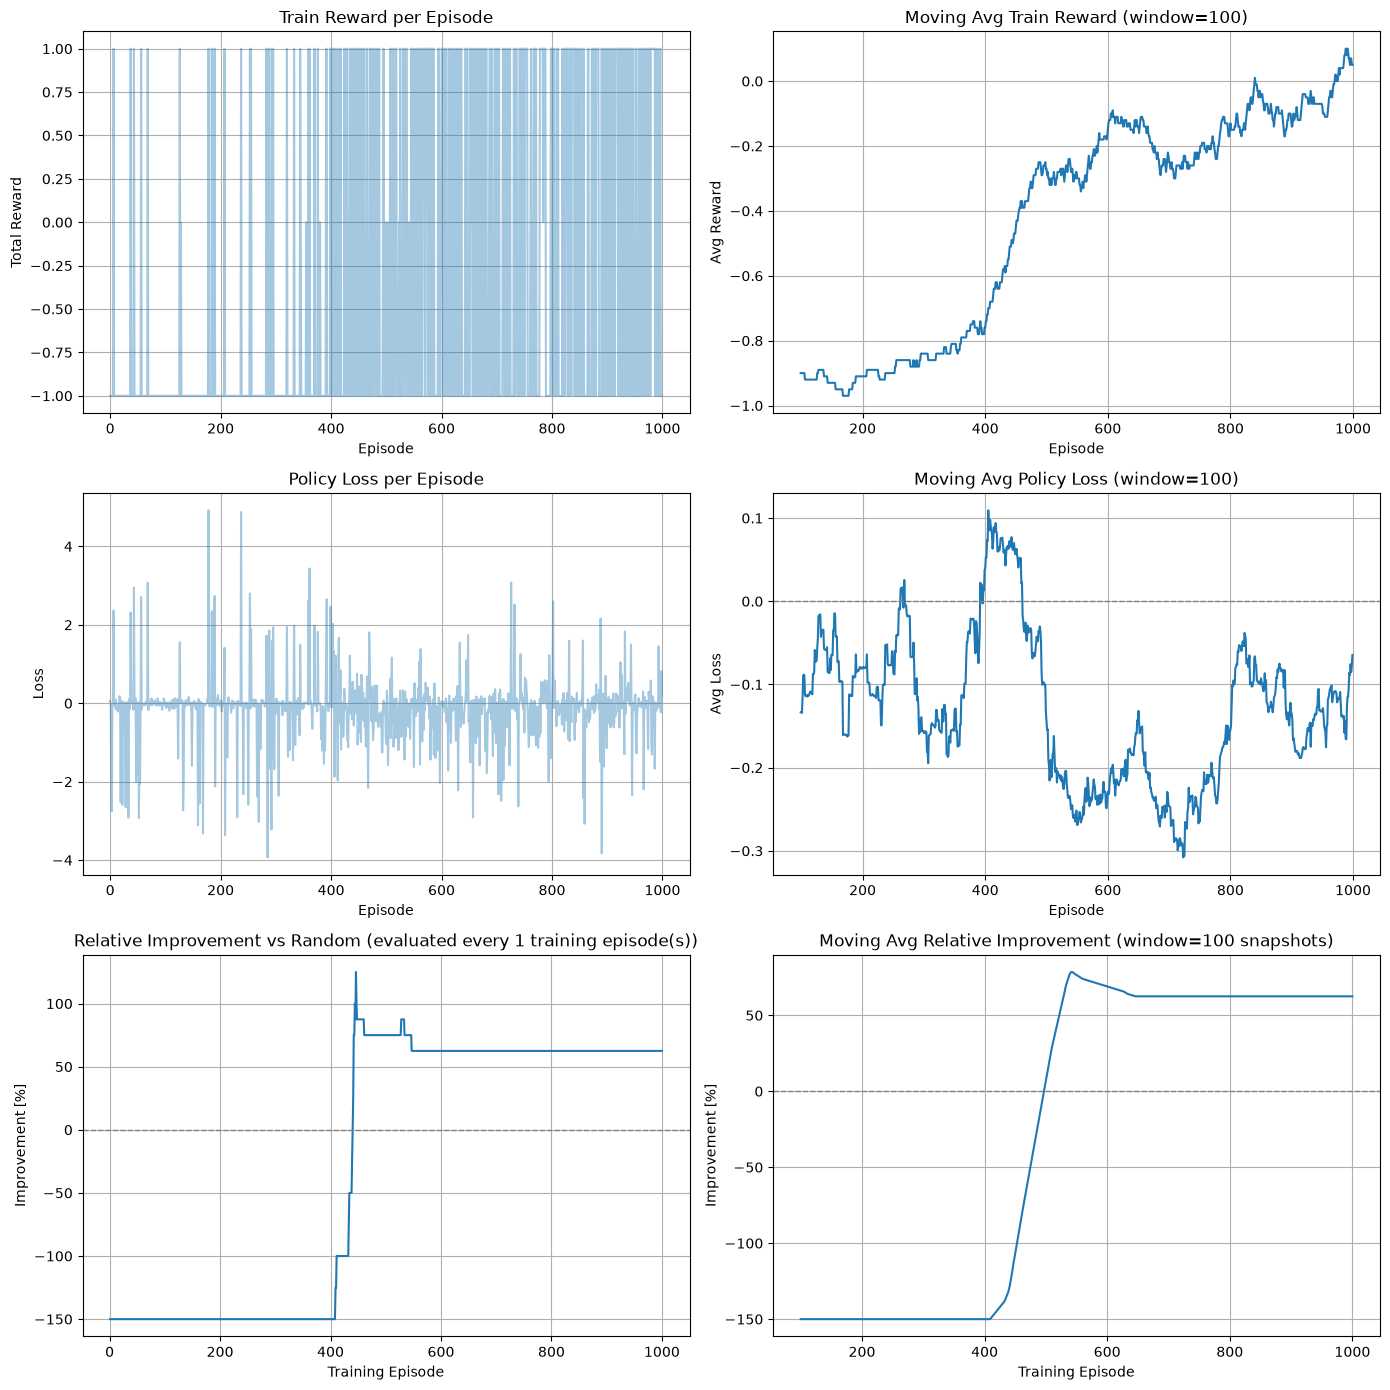

In [23]:
if __name__ == "__main__":
    # Set random seeds for reproducibility
    seed = 29
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Pick the agent class (REINFORCE)
    agent_class = REINFORCEAgent
    print(f"{agent_class.__name__} for Blackjack-v1")
    print("=" * 60)

    # Train the agent
    agent, rewards, losses, test_rewards, random_test_rewards = train_agent(
        AgentClass=agent_class,
        episodes=int(1e3),
        render=False
    )
    # agent.save_model("REINFORCE_blackjack_model.pth")

    # Print final statistics
    print(f"\nFinal Statistics:")
    print(f"  Average reward (last 100 episodes): {np.mean(rewards[-100:]):.2f}")
    print(f"  Best episode reward: {max(rewards):.2f}")
    if len(test_rewards) > 0:
        print(f"  Best total test reward snapshot: {np.max(test_rewards):.2f}")
        print(f"  Last total test reward snapshot: {test_rewards[-1]:.2f}")
    else:
        print("  No test snapshots collected.")

    # Plot results
    plot_training_results(rewards, losses, test_rewards, random_test_rewards)

    # Test the trained agent
    # agent.load_model("REINFORCE_blackjack_model.pth")
    eval_returns = test_agent(agent, episodes=20, render=True)


## Part 7: Bonus Questions 🌟
---
**Questions:**
 - Can policy network output logits instead of probabilities directly?
    <details>
    <summary>Answer</summary>

    - Yes, the policy network can output logits instead of probabilities directly. This is often done in practice, especially in the context of reinforcement learning. Potential advantages of using logits include improved numerical stability and better numerical properties during backpropagation. When using logits, the softmax function can be applied later to convert them into probabilities when needed, such as during action selection.
    </details>
- Are there any other improvements or modifications you would suggest for the REINFORCE algorithm to enhance its performance or stability?